# Resonator Spectroscopy and Fitting
This script is inspired by Ramya Suresh's resonator spectroscopy script

In [1]:
from malab import *
from numpy import *
from malab.datamanagement import SlabFile
from matplotlib.pyplot import *
import os, sys
# from tabulate import tabulate
from datetime import date, datetime
# from malab.dsfit import fitexp
# import pandas as pd
import json


No module named 'visa'
Warning VISA library import failed
Warning serial library import failed.
Could not load InstrumentManagerWindow


In [2]:
# plot formatting
font = {'family' : 'sans-serif',
        'style' : 'normal',
        'variant' : 'normal',
        'weight' : 'normal',
        'size'   : 18}
matplotlib.rc('font', **font)

## Resonator Spectroscopy

Connect to PNAX

In [ ]:
from malab.instruments import N5242A
pnax = N5242A("N5242A", address="xxx.xxx.xxx.xxx", timeout=10e3)
print('Deviced Connected:')
print(pnax.get_id())

In [ ]:
# exec(open('set_pulse_onoff.py').read()) does not matter now
# make sure you have set is_pulsed to 0 or 1 in set_pulse_onoff.py 
# depending on whether you want to do pulsed or CW measurement

Deviced Connected:
Keysight Technologies,N5242B,MY58422393,A.13.60.06



Passband Info for Data Saving if you want to save the data.

In [8]:
save_data = False
FullMsmtChain = 'PNAX_PORT1-VBFZ-3590S-VBFZ-4000-2-ZFSCSPLIT-1-50TERM-S-PNAX_PORT2'

PNAX measurement parameters

In [6]:
measurement = 'S21'  # S11,S21,S21,S22
sweep_points = 3001
ifbw = 1000
power = -20  #dBm
freq_startstop = [0.01, 16] #GHz
avgs = 5
freq_start = freq_startstop[0] * 1e9
freq_stop = freq_startstop[1] * 1e9

Configure Path

In [ ]:
expt_name = datetime.now().strftime("%Y%m%d_%H%M%S") + '_' + measurement + '_' + FullMsmtChain.replace('-', '_')
print('Experiment name: ' + expt_name)

folder_name = date.today().strftime("%Y%m%d") + ' - Shishir - Spectrum Analyzer QICK Test'
data_path = os.path.join(os.getcwd(), "data", folder_name) #list subfolders
os.makedirs(data_path, exist_ok=True) #safely nest folders if they don't exist already
print(data_path)

fname = get_next_filename(data_path, expt_name, suffix='.h5')
print('Current data file: ' + fname)

Experiment name: 20260316_091110_S21_PNAX_PORT1_VBFZ_3590S_VBFZ_4000_2_ZFSCSPLIT_1_50TERM_S_PNAX_PORT2
c:\Users\G41Lab\Dropbox\People\Shishir\PNAX\data\20260316 - Shishir - Spectrum Analyzer QICK Test
Current data file: 00000_20260316_091110_S21_PNAX_PORT1_VBFZ_3590S_VBFZ_4000_2_ZFSCSPLIT_1_50TERM_S_PNAX_PORT2.h5


Configure PNAX and Take One Sweep

In [8]:
pnax.configure(start=freq_start, stop=freq_stop, center=None, span=None,
                       power=power, ifbw=ifbw, sweep_points=sweep_points, averages=avgs)
pnax.set_frequency_offset_mode_state(False)
pnax.clear_traces()
pnax.setup_measurement(measurement)
pnax.set_output(1) #turn on RF power

In [ ]:
data = pnax.take_one_in_mag_phase()
freqs = data[0]
mags = data[1]
phases = data[2]

In [ ]:
# 1. Identify the peak and threshold
peak_idx = np.argmax(mags)
max_gain = mags[peak_idx]
threshold = max_gain - 3

# 2. Split arrays into left (rising) and right (falling) sides
mags_left = mags[:peak_idx]
freqs_left = freqs[:peak_idx]

mags_right = mags[peak_idx:]
freqs_right = freqs[peak_idx:]

# 3. Find the closest points to the -3dB threshold
# Left side (Lower Cutoff)
idx_l = np.argmin(np.abs(mags_left - threshold))
f_low = freqs_left[idx_l]

# Right side (Upper Cutoff)
idx_r = np.argmin(np.abs(mags_right - threshold))
f_high = freqs_right[idx_r]

# 4. Calculate Bandwidth and Q-Factor
bw = f_high - f_low
f_center = freqs[peak_idx]


print(f"Lower Cutoff: {f_low*1e-9:.3f} GHz")
print(f"Upper Cutoff: {f_high*1e-9:.3f} GHz")
print(f"Bandwidth:    {bw*1e-9:.3f} GHz")

Lower Cutoff: 5.063 GHz
Upper Cutoff: 6.385 GHz
Bandwidth:    1.322 GHz


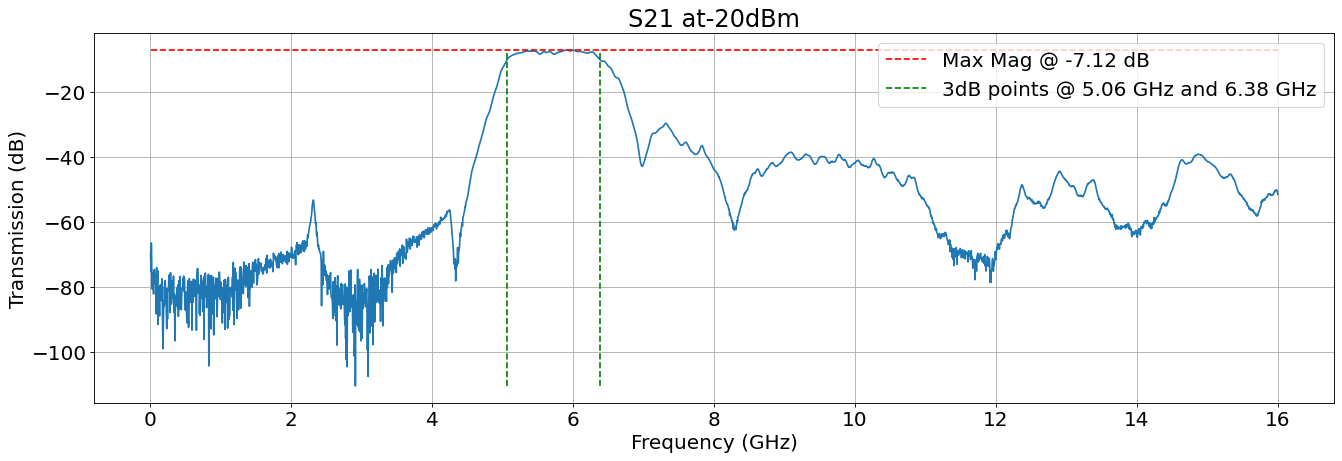

In [ ]:
figure(figsize=(20, 6), dpi=80)

plot(freqs / 1e9, mags)
xlabel('Frequency (GHz)')
ylabel('Transmission (dB)')
title(measurement + ' at' + str(power) + 'dBm')
hlines([max(mags)], xmin=min(freqs / 1e9), xmax=max(freqs / 1e9), colors='r', linestyles='dashed', label='Max Mag @ ' + str(round(max(mags), 2)) + ' dB')
vlines([f_low * 1e-9, f_high * 1e-9], ymin=min(mags), ymax=max(mags), colors='g', linestyles='dashed', label='3dB points @ ' + str(round(f_low*1e-9, 2)) + ' GHz' + ' and ' + str(round(f_high*1e-9, 2)) + ' GHz')
legend()
grid()

Save Data as a SLab (Schuster Lab) file

In [ ]:
if save_data:
        with SlabFile(data_path + '\\' + fname, 'a') as f:

                f.note('Frequency Range = ' + str(freq_start / 1e9) + 'GHz to ' + str(freq_stop / 1e9) + 'GHz')
                f.note('Power = ' + str(power) + 'dBm')
                f.note('Full Measurement Chain: ' + FullMsmtChain)
                f.note('IFBW = ' + str(int(ifbw / 1e3)) + 'kHz')
                f.note('No of Sweep Points = ' + str(int(sweep_points)))
                f.note('No of Averages = ' + str(avgs))
                f.note('Time = ' + str(datetime.now().strftime("%d/%m/%Y %H:%M:%S")))

                # 'a': read/write/create

                f.append('freqs', freqs)
                f.append('mags', mags)
                f.append('phases', phases)

                # f.add('freqs',fake_freq)
                # f.add('mags', fake_mag)
                # f.add('phases', fake_phase)

                # append will append to existing data, add will replace existing data.
                # note the different dimensions between the two methods

In [ ]:
pnax.set_output(0) #turn off RF power

## Spectrum Analyzer

Can be used for comparing with VNA passband or seeing the output spectrum of anything

In [3]:
freq_startstop = [3.5, 5.5] #GHz
# avgs = 3
freq_start = freq_startstop[0] * 1e9
freq_stop = freq_startstop[1] * 1e9
sweep_points = int(8192/1)

In [2]:
from malab.instruments import E4440
sa = E4440(address='xxx.xxx.xxx.xxx')
print('Deviced Connected:')
print(sa.get_id())

Deviced Connected:
Agilent Technologies, E4440A, US45303066, A.11.21



In [75]:
sa.set_start_frequency(freq_start) 
sa.set_stop_frequency(freq_stop)   
sa.set_sweep_points(sweep_points)     # Set number of points max 8192
sa.set_averages(avgs)  # Set number of averages
sa.set_average_state(False)  # Enable averaging
sa.set_resbw(3e6)  # Set IF bandwidth 8 MHz max


In [4]:
fpts = np.linspace(freq_start, freq_stop, sweep_points)

In [7]:
expt_config = {
    'gen_ch': [0,1], # 0/9 is qubit drive, 1 is readout
    'synced' : 0, # 0 or 1 for qubit or readout DAC synced to ADC
    'nqz': [1,2],
    'ro_ch': 0,
    'freq': [4000,5500], # MHz
    'trig_time': 0,
    'ro_len': 1.9,
    'gain': 1, # 0.1,
    'enabled' : [0,1] # 1 is on, 0 is off (for spectrum analyzer measuremet)
    # 'mixer_freq': 4500,
}

In [5]:
sa.write(":FORM:DATA ASC")
sa.query_sleep = 5  # give it time
sa.write("*CLS")
sa.set_timeout(0.5)
try:
    while True:
        s = sa.read()
        if s is None:
            break
except:
    pass

result = sa.query(":TRAC:DATA? TRACE1")
print(type(result), len(result) if result else "None")

<class 'str'> 106496


In [9]:
result

'-8.56290E+01,-8.67600E+01,-8.42380E+01,-8.60430E+01,-8.70460E+01,-8.68270E+01,-8.60760E+01,-8.60590E+01,-8.72160E+01,-8.67890E+01,-8.57240E+01,-8.54330E+01,-8.73230E+01,-8.62930E+01,-8.83810E+01,-8.63330E+01,-8.55630E+01,-8.64020E+01,-8.48320E+01,-8.66760E+01,-8.87830E+01,-8.55000E+01,-8.55890E+01,-8.65170E+01,-8.74120E+01,-8.73040E+01,-8.42200E+01,-8.65190E+01,-8.62980E+01,-8.36100E+01,-8.78360E+01,-8.79770E+01,-8.68370E+01,-8.97490E+01,-8.62120E+01,-8.52540E+01,-8.80710E+01,-8.76580E+01,-8.73720E+01,-8.88830E+01,-8.71250E+01,-8.90460E+01,-8.71290E+01,-8.54540E+01,-8.78460E+01,-8.77960E+01,-8.76980E+01,-8.37650E+01,-8.47270E+01,-8.40350E+01,-8.64360E+01,-8.95560E+01,-8.66940E+01,-8.68940E+01,-8.52510E+01,-8.69020E+01,-8.63840E+01,-8.76430E+01,-8.43300E+01,-8.77330E+01,-8.74660E+01,-8.62620E+01,-8.76080E+01,-8.64880E+01,-8.53160E+01,-8.63220E+01,-8.66780E+01,-8.35920E+01,-8.57800E+01,-8.50610E+01,-8.64930E+01,-8.50190E+01,-8.46580E+01,-8.67300E+01,-8.80650E+01,-8.23200E+01,-8.87260E+0

In [6]:
powerdB_sa = np.fromstring(result, dtype=float, sep=',')
len(powerdB_sa)

#(fpts, powerdB_sa) = sa.take_one()

8192

In [7]:
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

noise_floor = np.median(powerdB_sa)
noise_std = np.std(powerdB_sa)
snr_threshold = noise_floor + 2.7 * noise_std  # adjust multiplier to taste

peak_indices, properties = find_peaks(
    powerdB_sa,
    height=snr_threshold,    # must be above noise floor + N*std
    distance=50,             # minimum samples between peaks, tune to your resolution
    prominence=0            # must stand out from surroundings
)

peaks = fpts[peak_indices] / 1e9
peak_powers = powerdB_sa[peak_indices]

print(f"Noise floor: {noise_floor:.1f} dBm")
print(f"SNR threshold: {snr_threshold:.1f} dBm")
print(f"Found {len(peak_indices)} peaks:")
for f, p in zip(peaks, peak_powers):
    print(f"  {f:.3f} GHz  →  {p:.1f} dBm")

Noise floor: -90.2 dBm
SNR threshold: -67.0 dBm
Found 3 peaks:
  3.916 GHz  →  -49.0 dBm
  4.500 GHz  →  3.1 dBm
  5.085 GHz  →  -7.0 dBm


Peak in 0.0-10.0 GHz range: 4.50 GHz
Magnitude of Peak: 3.057 dBm


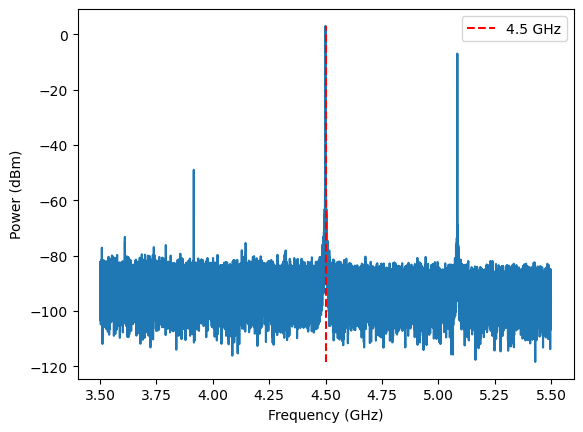

In [8]:
lower_bound = 0e9
upper_bound = 10e9

append = True
index = 0

fpts_indices = np.where((fpts >= lower_bound) & (fpts <= upper_bound))
fpts_short = fpts[fpts_indices]
mags_short = powerdB_sa[fpts_indices]
f_max = np.where(mags_short == np.max(mags_short))[0][0]
print(f"Peak in {lower_bound/1e9}-{upper_bound/1e9} GHz range: {fpts_short[f_max] / 1e9:.2f} GHz")
print("Magnitude of Peak: " + str(np.max(mags_short)) + " dBm")

plot(fpts_short / 1e9, mags_short)
vlines([fpts_short[f_max] / 1e9], ymin=min(mags_short), ymax=max(mags_short), colors='r', linestyles='dashed', label=str(round(fpts_short[f_max] / 1e9, 2)) + ' GHz')
xlabel("Frequency (GHz)") 
ylabel("Power (dBm)")
legend()

if append:
    peaks = np.insert(peaks, index, fpts_short[f_max] / 1e9)
    peak_powers = np.insert(peak_powers, index, np.max(mags_short))

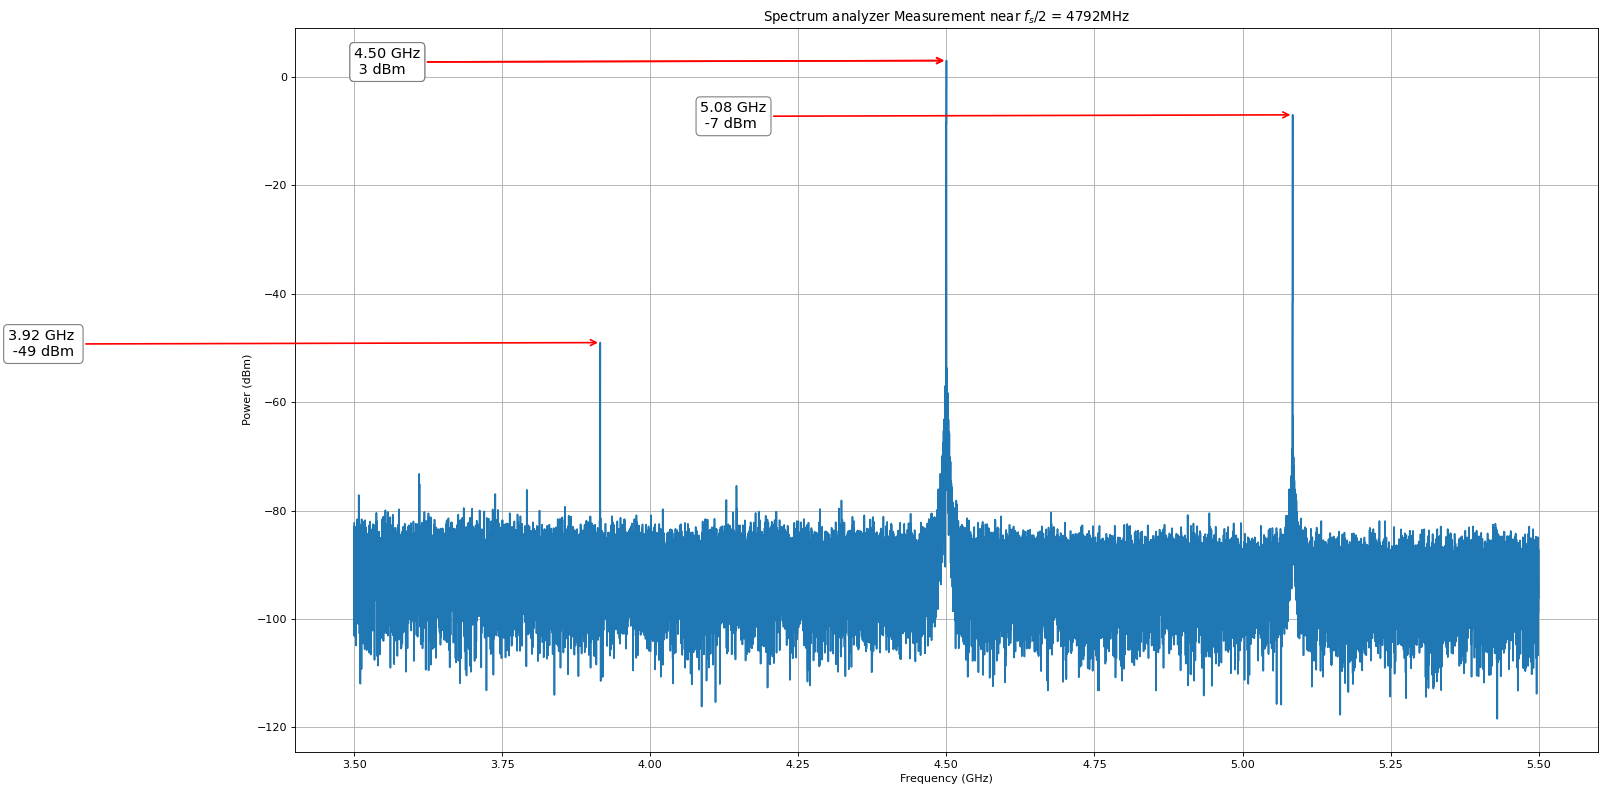

In [15]:
fig, ax = plt.subplots(figsize=(20, 10), dpi=80)
ax.plot(fpts / 1e9, powerdB_sa)
# 
#labels = ["$2f_s - 2f$ ","", "$f$", "","",""] # "$2f$" ] #,"$|f_s - 4f|$", "$2f_s - f$", "$f_s + f$","$4f_s − 4f$", "$3f_s − 2f$", "$2f_s$", "$f_s + 2f$"]  # Example labels for peaks
for freq, power in zip(peaks, peak_powers): # zip([2.8, 6.5, 13], [-90, -90, -90]):  # 
    ax.annotate(
        f'{freq:.2f} GHz\n {power:.0f} dBm ',
        xy=(freq, power),                        # arrow tip (the peak)
        xytext=(freq - 1, power - 2.5),         # label position
        fontsize=13,
        ha='left',
        arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray', alpha=1)
    )

ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel('Power (dBm)')
ax.set_title(r"Spectrum analyzer Measurement near $f_s$/2 = 4792MHz")
#ax.vlines([2.8, 6.5, 13], ymin=min(powerdB_sa), ymax=max(powerdB_sa), colors='r', linestyles='dashed', label='Identified Peaks')
ax.grid()
plt.tight_layout()
plt.show()
#print(len(peaks), len(peak_powers), len(labels))

In [110]:
save_sa_data = True
dac_info = "wideband_qubit_gen_9_gain=1_5.5GHz"
folder_name = date.today().strftime("%Y%m%d") + ' - Shishir - PUR1D4 DAC Spectrum After Filters'
data_path = os.path.join(os.getcwd(), "data", folder_name) #list subfolders
os.makedirs(data_path, exist_ok=True) #safely nest folders if they don't exist already
print(data_path)
fname = get_next_filename(data_path, dac_info + '_SA', suffix='.h5')

c:\Users\G41Lab\Dropbox\People\Shishir\PNAX\data\20260402 - Shishir - PUR1D4 DAC Spectrum After Filters


In [111]:
if save_sa_data:
    with SlabFile(data_path + '\\' + fname, 'a') as f:
        f.append('freqs', fpts)
        f.append('mags', powerdB_sa)
        f.append('peaks_freqs', peaks)
        f.append('peaks_powers', peak_powers)

## Make a combined plot

In [ ]:
sa_filename = r"C:\Users\G41Lab\Dropbox\People\Shishir\PNAX\data\20260304 - Shishir - Passband VNA Test\00000_axis_signal_gen_v6_fs_9584MHz_SA.h5"
vna_filename = r"C:\Users\G41Lab\Dropbox\People\Shishir\PNAX\data\20260225 - Shishir - Passband VNA Test\00000_20260225_225714_S21_PNAX_PORT1_VLF5850_VHF5050_VHF5050_2_ZFSCSPLIT_1_50TERM_S_PNAX_PORT2.h5"
#include the whole path

In [ ]:
from tabulate import tabulate
with SlabFile(sa_filename, 'r') as f:

    print(tabulate(list(f.items())))

    sa_freqs =   array(f['freqs'])[0]
    sa_mags  = array(f['mags'])[0]

with SlabFile(vna_filename, 'r') as f:

    print(tabulate(list(f.items())))

    freqs =   array(f['freqs'])[0]
    mags  = array(f['mags'])[0]
    phases = array(f['phases'])[0]

-----  ---------------------------------------------------
freqs  <HDF5 dataset "freqs": shape (1, 6002), type "<f8">
mags   <HDF5 dataset "mags": shape (1, 6002), type "<f8">
-----  ---------------------------------------------------
------  ----------------------------------------------------
freqs   <HDF5 dataset "freqs": shape (1, 3001), type "<f8">
mags    <HDF5 dataset "mags": shape (1, 3001), type "<f8">
notes   <HDF5 dataset "notes": shape (7,), type "|O">
phases  <HDF5 dataset "phases": shape (1, 3001), type "<f8">
------  ----------------------------------------------------


In [ ]:
# 1. Identify the peak and threshold
peak_idx = np.argmax(mags)
max_gain = mags[peak_idx]
threshold = max_gain - 3

# 2. Split arrays into left (rising) and right (falling) sides
mags_left = mags[:peak_idx]
freqs_left = freqs[:peak_idx]

mags_right = mags[peak_idx:]
freqs_right = freqs[peak_idx:]

# 3. Find the closest points to the -3dB threshold
# Left side (Lower Cutoff)
idx_l = np.argmin(np.abs(mags_left - threshold))
f_low = freqs_left[idx_l]

# Right side (Upper Cutoff)
idx_r = np.argmin(np.abs(mags_right - threshold))
f_high = freqs_right[idx_r]

# 4. Calculate Bandwidth and Q-Factor
bw = f_high - f_low
f_center = freqs[peak_idx]


print(f"Lower Cutoff: {f_low*1e-9:.3f} GHz")
print(f"Upper Cutoff: {f_high*1e-9:.3f} GHz")
print(f"Bandwidth:    {bw*1e-9:.3f} GHz")

Lower Cutoff: 5.052 GHz
Upper Cutoff: 6.411 GHz
Bandwidth:    1.359 GHz


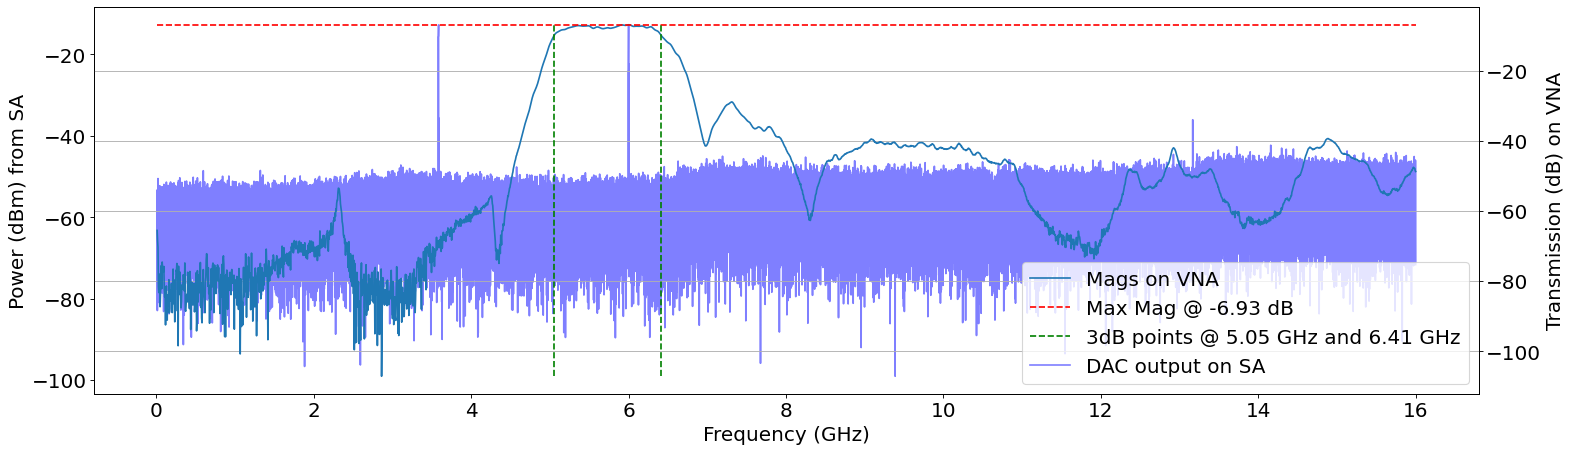

In [ ]:
fig, ax1 = plt.subplots(figsize=(20, 6), dpi=80)


ax1.plot(sa_freqs / 1e9, sa_mags, color='blue', label='DAC output on SA', alpha=0.5)
ax1.set_ylabel('Power (dBm) from SA')
ax1.set_xlabel('Frequency (GHz)')
ax2 = ax1.twinx()
ax2.plot(freqs / 1e9, mags, label='Mags on VNA')
ax2.set_ylabel('Transmission (dB) on VNA')
ax2.hlines([max(mags)], xmin=min(freqs / 1e9), xmax=max(freqs / 1e9), colors='r', linestyles='dashed', label='Max Mag @ ' + str(round(max(mags), 2)) + ' dB')
ax2.vlines([f_low * 1e-9, f_high * 1e-9], ymin=min(mags), ymax=max(mags), colors='g', linestyles='dashed', label='3dB points @ ' + str(round(f_low*1e-9, 2)) + ' GHz' + ' and ' + str(round(f_high*1e-9, 2)) + ' GHz')


lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax1.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2)

ax2.grid()
plt.tight_layout()
plt.show()